# 1. Título
**Síndrome dos Ovários Policísticos (SOP/PCOS): perfil clínico, hormonal e ultrassonográfico**

DCC011 - Introdução a Bancos de Dados

# 2. Membros (nome e número de matrícula)

- Maria Eduarda Araujo
- Julia Machado
- Luisa Marques
- Mariana Villefort
- Talvani de Souza

# 3. Descrição dos dados (qual a URL? qual o domínio? como os dados foram processados?)

**URL:** https://www.kaggle.com/datasets/prasoonkottarathil/polycystic-ovary-syndrome-pcos

**Domínio:** saúde da mulher, mais especificamente a Síndrome dos Ovários Policísticos (SOP). O dataset *Polycystic ovary syndrome (PCOS)* foi publicado no Kaggle por Prasoon Kottarathil em 2020 e reúne dados de **541 mulheres** atendidas em 10 hospitais de Kerala (Índia), das quais **177 têm diagnóstico de SOP**.

**Como obter os dados:** (1) criar uma conta gratuita no Kaggle; (2) acessar a URL acima e clicar em *Download*; (3) extrair o arquivo `PCOS_data_without_infertility.xlsx` e colocá-lo na mesma pasta deste notebook. Usamos a aba `Full_new` (541 linhas, 44 colunas com nome). O outro arquivo do dataset, `PCOS_infertility.csv`, contém as mesmas pacientes e repete colunas já presentes no xlsx, por isso não foi usado.

**Como os dados foram processados (projeto bottom-up):** a planilha original é uma única tabela larga, com uma linha por paciente. Ela foi decomposta nas relações do esquema das seções 4 e 5:

1. **Paciente:** uma tupla por paciente, identificada pelo nº do prontuário (`Patient File No.`). O ciclo menstrual, codificado como 2 (regular) e 4 (irregular), foi convertido para `'R'`/`'I'`; o único valor 5 não tem significado na codificação e foi gravado como `NULL`.
2. **TipoSanguineo:** os códigos 11 a 18 foram decodificados em grupo ABO e fator Rh, conforme a aba `Instructions` da própria planilha. Assim o tipo sanguíneo é armazenado uma única vez e referenciado por chave estrangeira.
3. **TipoExame + Realiza:** as 11 colunas de exames laboratoriais (FSH, LH, AMH, TSH, prolactina, progesterona, vitamina D3, beta-HCG I e II, glicemia e hemoglobina) viraram linhas da relação associativa `Realiza(id_paciente, id_exame, valor)`. O valor `'1.99.'` (beta-HCG II da paciente 124) foi corrigido para 1.99 (erro de digitação); o valor `'a'` (AMH da paciente 306) não é numérico e foi descartado.
4. **Sintoma + Apresenta** e **Habito + Pratica:** as colunas sim/não de 5 sintomas e 2 hábitos viraram linhas das relações associativas `Apresenta` e `Pratica`. Só as respostas “sim” geram tupla; o único valor ausente (fast food de uma paciente) não gera associação.
5. **AvaliacaoOvariana:** as colunas do ovário esquerdo e direito viraram duas tuplas por paciente, identificadas por `(id_paciente, lado)`. É a entidade fraca do modelo: o dono é a paciente e o lado é a chave parcial.
6. **Atributos derivados:** IMC, razão cintura/quadril e razão FSH/LH são calculáveis a partir de outros atributos (peso e altura; cintura e quadril; exames FSH e LH). Para evitar redundância e inconsistência, **não são armazenados**: aparecem no ER como atributos derivados e são calculados pela visão `vw_paciente_indices`.

Com isso, todo valor das tabelas é atômico e grupos de colunas de mesmo significado foram transformados em tuplas de relações associativas.

In [1]:
import sqlite3
import pandas as pd
from IPython.display import display

ARQUIVO = 'PCOS_data_without_infertility.xlsx'   # baixado do Kaggle (ver seção 3)
df = pd.read_excel(ARQUIVO, sheet_name='Full_new', dtype=str)
df.columns = [c.strip() for c in df.columns]
df = df.drop(columns=[c for c in df.columns if c.startswith('Unnamed')])
dados = df.fillna('').to_dict('records')
print('Registros carregados:', len(dados), '| Colunas:', len(df.columns))
assert len(dados) == 541

Registros carregados: 541 | Colunas: 44


In [2]:
import math

def num(v):
    if v is None or str(v).strip() == '': return None
    try:
        z = float(str(v).strip())
        return z if math.isfinite(z) else None
    except ValueError:
        return None

def inteiro(v):
    z = num(v)
    return int(z) if z is not None else None

# correções documentadas na seção 3
CORRECOES = {(124, 'II    beta-HCG(mIU/mL)'): '1.99'}
CICLO = {2: 'R', 4: 'I'}   # código 5 não existe na codificação -> NULL

sintomas = [
    (1,'Ganho de peso','Ganho de peso relatado','Weight gain(Y/N)'),
    (2,'Crescimento de pelos','Crescimento excessivo de pelos relatado','hair growth(Y/N)'),
    (3,'Escurecimento da pele','Escurecimento da pele relatado','Skin darkening (Y/N)'),
    (4,'Queda de cabelo','Queda de cabelo relatada','Hair loss(Y/N)'),
    (5,'Espinhas','Presença de espinhas (acne)','Pimples(Y/N)'),
]
habitos = [
    (1,'Consumo de fast food','Consumo frequente de fast food','Fast food (Y/N)'),
    (2,'Exercício regular','Prática regular de exercício físico','Reg.Exercise(Y/N)'),
]
exames = [
    (1,'Beta-HCG I','mIU/mL','Hormonal','I   beta-HCG(mIU/mL)'),
    (2,'Beta-HCG II','mIU/mL','Hormonal','II    beta-HCG(mIU/mL)'),
    (3,'FSH','mIU/mL','Hormonal','FSH(mIU/mL)'),
    (4,'LH','mIU/mL','Hormonal','LH(mIU/mL)'),
    (5,'TSH','mIU/L','Hormonal','TSH (mIU/L)'),
    (6,'AMH','ng/mL','Hormonal','AMH(ng/mL)'),
    (7,'Prolactina','ng/mL','Hormonal','PRL(ng/mL)'),
    (8,'Vitamina D3','ng/mL','Bioquímico','Vit D3 (ng/mL)'),
    (9,'Progesterona','ng/mL','Hormonal','PRG(ng/mL)'),
    (10,'Glicemia casual','mg/dL','Bioquímico','RBS(mg/dl)'),
    (11,'Hemoglobina','g/dL','Hematológico','Hb(g/dl)'),
]
tipos_sangue = [(11,'A','+'),(12,'A','-'),(13,'B','+'),(14,'B','-'),
                (15,'O','+'),(16,'O','-'),(17,'AB','+'),(18,'AB','-')]
print('Exames:', len(exames), '| Sintomas:', len(sintomas), '| Hábitos:', len(habitos))

Exames: 11 | Sintomas: 5 | Hábitos: 2


In [3]:
con = sqlite3.connect(':memory:')
con.execute('PRAGMA foreign_keys = ON')
con.executescript('''
CREATE TABLE TipoSanguineo(
  codigo     INTEGER PRIMARY KEY,
  grupo_abo  TEXT NOT NULL CHECK (grupo_abo IN ('A','B','AB','O')),
  fator_rh   TEXT NOT NULL CHECK (fator_rh IN ('+','-')));

CREATE TABLE Paciente(
  id_paciente       INTEGER PRIMARY KEY,
  codigo_sangue     INTEGER NOT NULL REFERENCES TipoSanguineo(codigo),
  pcos              INTEGER NOT NULL CHECK (pcos IN (0,1)),
  idade             INTEGER,
  peso_kg           REAL,
  altura_cm         REAL,
  cintura_pol       REAL,
  quadril_pol       REAL,
  pulso_bpm         INTEGER,
  freq_respiratoria INTEGER,
  pa_sistolica      INTEGER,
  pa_diastolica     INTEGER,
  tipo_ciclo        TEXT CHECK (tipo_ciclo IN ('R','I')),
  duracao_ciclo     INTEGER,
  gestante          INTEGER CHECK (gestante IN (0,1)),
  n_abortos         INTEGER,
  anos_casamento    REAL,
  endometrio_mm     REAL);

CREATE TABLE TipoExame(
  id_exame   INTEGER PRIMARY KEY,
  nome       TEXT NOT NULL,
  unidade    TEXT NOT NULL,
  categoria  TEXT NOT NULL);

CREATE TABLE Sintoma(
  id_sintoma INTEGER PRIMARY KEY,
  nome       TEXT NOT NULL,
  descricao  TEXT NOT NULL);

CREATE TABLE Habito(
  id_habito  INTEGER PRIMARY KEY,
  nome       TEXT NOT NULL,
  descricao  TEXT NOT NULL);

CREATE TABLE AvaliacaoOvariana(
  id_paciente          INTEGER NOT NULL,
  lado                 TEXT NOT NULL CHECK (lado IN ('E','D')),
  quantidade_foliculos INTEGER,
  tamanho_medio_mm     REAL,
  PRIMARY KEY (id_paciente, lado),
  FOREIGN KEY (id_paciente) REFERENCES Paciente(id_paciente) ON DELETE CASCADE);

CREATE TABLE Realiza(
  id_paciente INTEGER NOT NULL,
  id_exame    INTEGER NOT NULL,
  valor       REAL NOT NULL,
  PRIMARY KEY (id_paciente, id_exame),
  FOREIGN KEY (id_paciente) REFERENCES Paciente(id_paciente) ON DELETE CASCADE,
  FOREIGN KEY (id_exame)    REFERENCES TipoExame(id_exame));

CREATE TABLE Apresenta(
  id_paciente INTEGER NOT NULL,
  id_sintoma  INTEGER NOT NULL,
  PRIMARY KEY (id_paciente, id_sintoma),
  FOREIGN KEY (id_paciente) REFERENCES Paciente(id_paciente) ON DELETE CASCADE,
  FOREIGN KEY (id_sintoma)  REFERENCES Sintoma(id_sintoma));

CREATE TABLE Pratica(
  id_paciente INTEGER NOT NULL,
  id_habito   INTEGER NOT NULL,
  PRIMARY KEY (id_paciente, id_habito),
  FOREIGN KEY (id_paciente) REFERENCES Paciente(id_paciente) ON DELETE CASCADE,
  FOREIGN KEY (id_habito)   REFERENCES Habito(id_habito));

-- atributos derivados: calculados, não armazenados
CREATE VIEW vw_paciente_indices AS
SELECT id_paciente, pcos, idade,
       ROUND(peso_kg / ((altura_cm/100.0) * (altura_cm/100.0)), 2) AS imc,
       ROUND(cintura_pol / quadril_pol, 2) AS razao_cintura_quadril
FROM Paciente;
''')

con.executemany('INSERT INTO TipoSanguineo VALUES (?,?,?)', tipos_sangue)
con.executemany('INSERT INTO TipoExame VALUES (?,?,?,?)', [e[:4] for e in exames])
con.executemany('INSERT INTO Sintoma VALUES (?,?,?)', [s[:3] for s in sintomas])
con.executemany('INSERT INTO Habito VALUES (?,?,?)', [h[:3] for h in habitos])

campos = ['Blood Group','PCOS (Y/N)','Age (yrs)','Weight (Kg)','Height(Cm)','Waist(inch)','Hip(inch)',
          'Pulse rate(bpm)','RR (breaths/min)','BP _Systolic (mmHg)','BP _Diastolic (mmHg)']
descartados = []
for d in dados:
    pid = inteiro(d['Patient File No.'])
    ciclo = CICLO.get(inteiro(d['Cycle(R/I)']))
    linha = [pid] + [num(d[c]) for c in campos] + [
        ciclo, num(d['Cycle length(days)']), inteiro(d['Pregnant(Y/N)']), inteiro(d['No. of aborptions']),
        num(d['Marraige Status (Yrs)']), num(d['Endometrium (mm)'])]
    con.execute('INSERT INTO Paciente VALUES (' + ','.join(['?'] * len(linha)) + ')', linha)
    for eid, nome, unidade, cat, col in exames:
        bruto = CORRECOES.get((pid, col), d[col])
        z = num(bruto)
        if z is not None:
            con.execute('INSERT INTO Realiza VALUES (?,?,?)', (pid, eid, z))
        else:
            descartados.append((pid, col.strip(), d[col]))
    for sid, nome, descr, col in sintomas:
        if inteiro(d[col]) == 1: con.execute('INSERT INTO Apresenta VALUES (?,?)', (pid, sid))
    for hid, nome, descr, col in habitos:
        if inteiro(d[col]) == 1: con.execute('INSERT INTO Pratica VALUES (?,?)', (pid, hid))
    for lado, n_col, t_col in [('E','Follicle No. (L)','Avg. F size (L) (mm)'),
                               ('D','Follicle No. (R)','Avg. F size (R) (mm)')]:
        con.execute('INSERT INTO AvaliacaoOvariana VALUES (?,?,?,?)',
                    (pid, lado, inteiro(d[n_col]), num(d[t_col])))
con.commit()

qtd = pd.read_sql_query("SELECT name AS tabela FROM sqlite_master WHERE type='table' ORDER BY name", con)
qtd['tuplas'] = [con.execute('SELECT COUNT(*) FROM ' + t).fetchone()[0] for t in qtd.tabela]
display(qtd)
print('Valores descartados (não numéricos):', descartados)
print('Diagnóstico (0 = sem SOP, 1 = com SOP):', con.execute('SELECT pcos, COUNT(*) FROM Paciente GROUP BY pcos').fetchall())
print('Ciclo:', con.execute('SELECT tipo_ciclo, COUNT(*) FROM Paciente GROUP BY tipo_ciclo').fetchall())
print('Violações de integridade referencial:', con.execute('PRAGMA foreign_key_check').fetchall())

,tabela,tuplas
0,Apresenta,1028
1,AvaliacaoOvariana,1082
2,Habito,2
3,Paciente,541
4,Pratica,412
5,Realiza,5950
6,Sintoma,5
7,TipoExame,11
8,TipoSanguineo,8


Valores descartados (não numéricos): [(306, 'AMH(ng/mL)', 'a')]
Diagnóstico (0 = sem SOP, 1 = com SOP): [(0, 364), (1, 177)]
Ciclo: [(None, 1), ('I', 150), ('R', 390)]
Violações de integridade referencial: []


**Resultado da carga:** as 9 tabelas correspondem às 6 entidades do ER (Paciente, TipoSanguineo, TipoExame, Sintoma, Habito e AvaliacaoOvariana) e às 3 tabelas criadas pelos relacionamentos M:N (Realiza, Apresenta e Pratica). Os relacionamentos POSSUI (N:1) e TEM (1:N, identificador) não geram tabela própria: POSSUI vira a chave estrangeira `codigo_sangue` em Paciente, e TEM é representado pela chave estrangeira `id_paciente`, que também compõe a chave primária de AvaliacaoOvariana. Realiza tem 5.950 tuplas, uma a mais que o informado na proposta (5.949), porque o beta-HCG II da paciente 124 passou a ser aproveitado após a correção do erro de digitação.

# 4. Diagrama ER

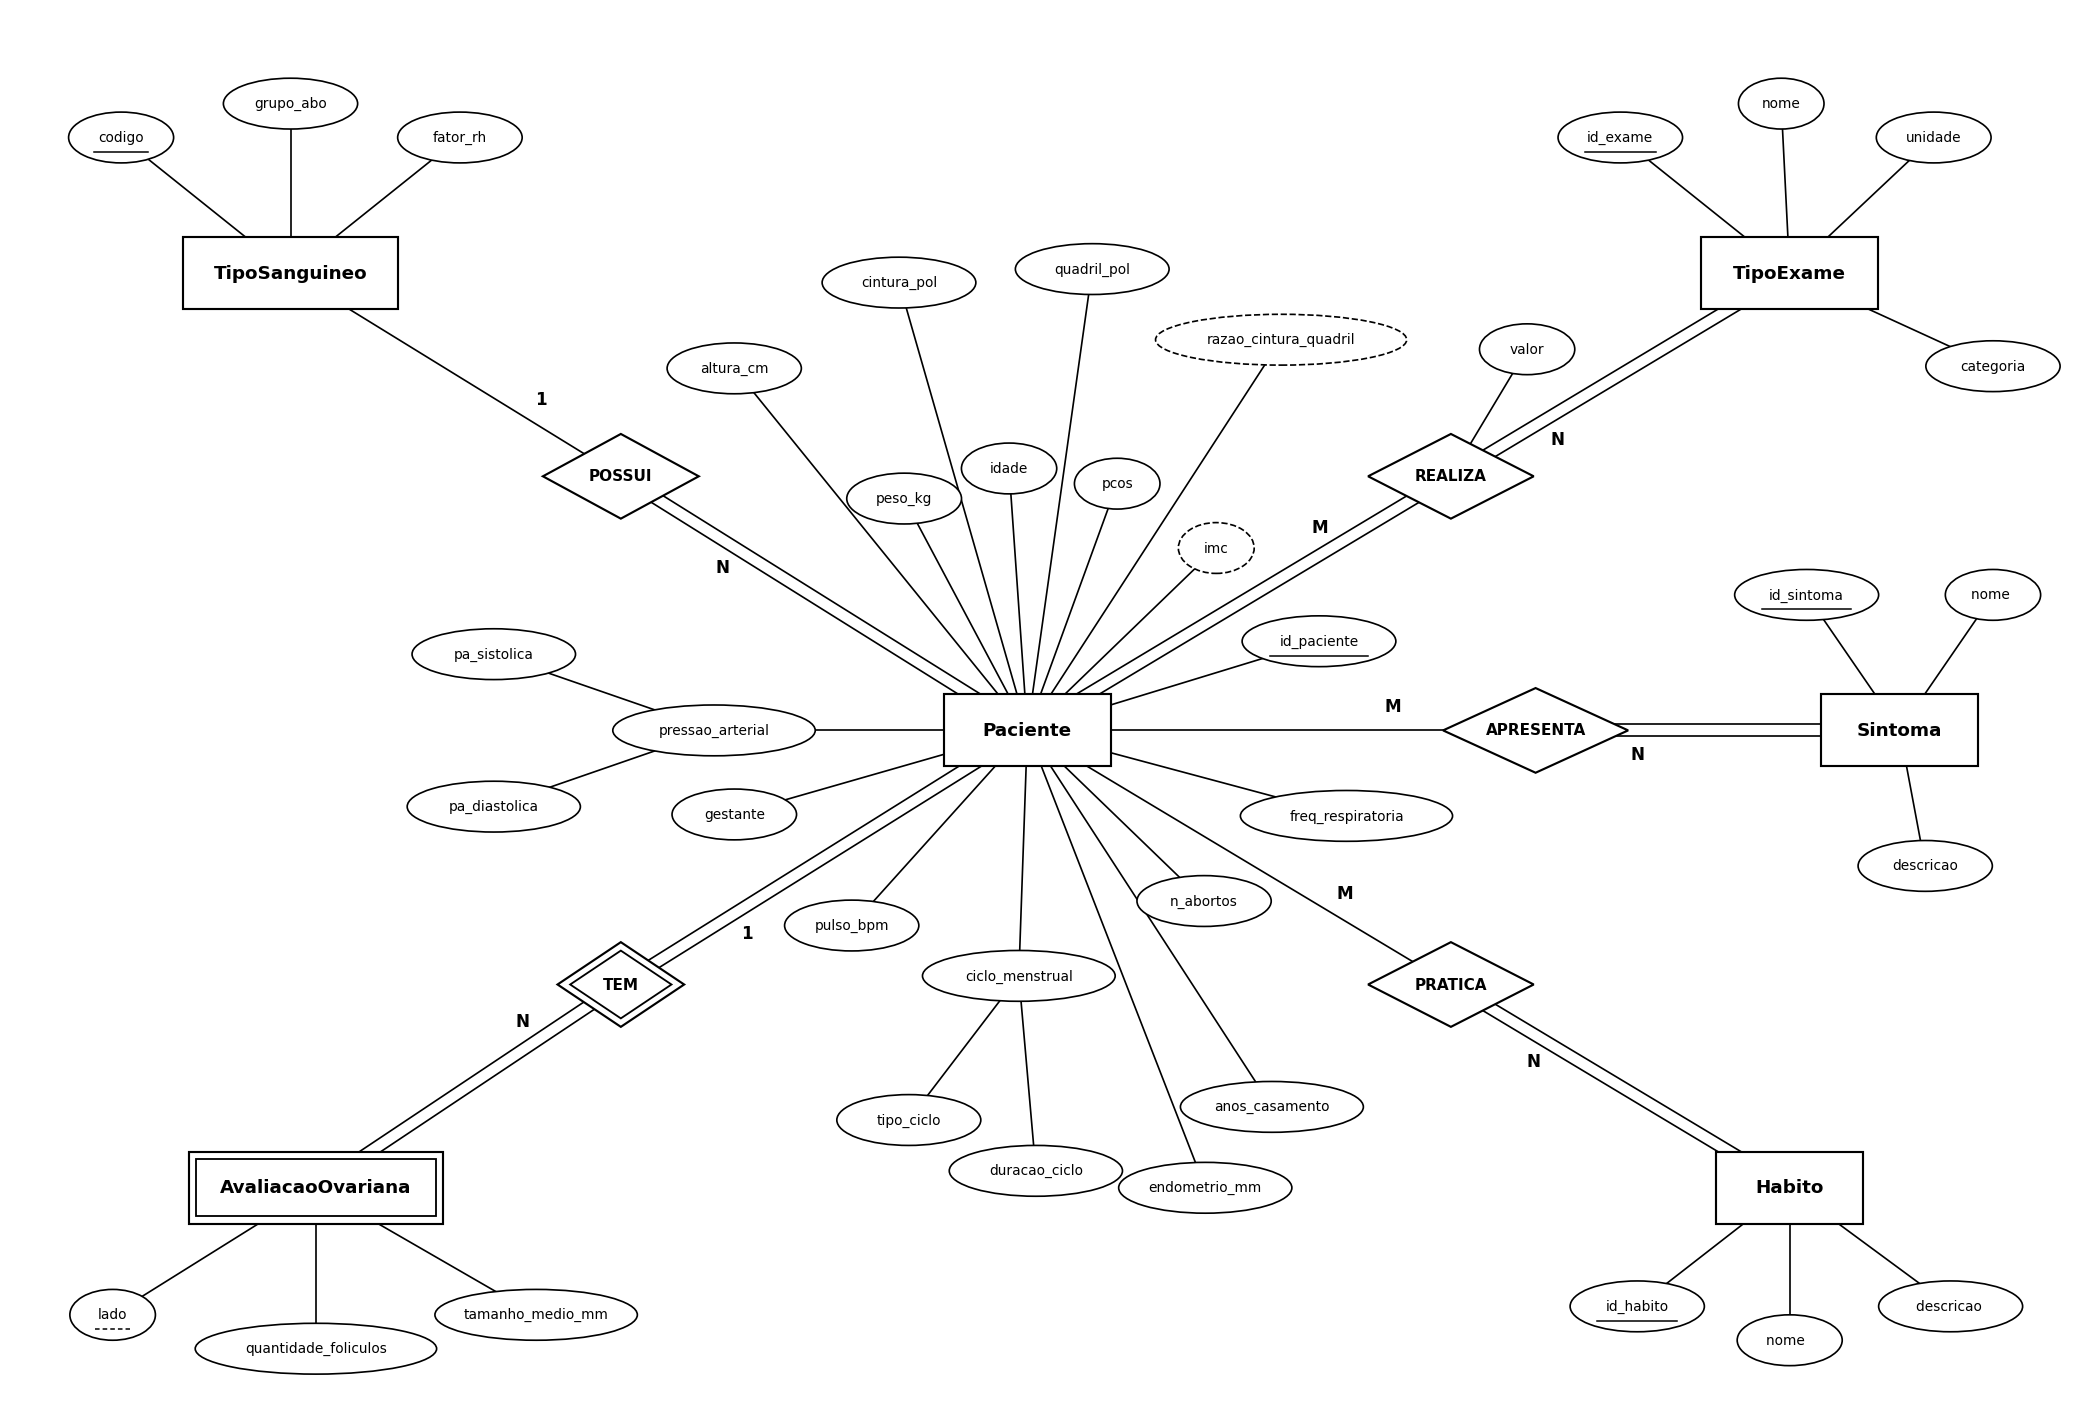

**Notação (Elmasri & Navathe):** retângulo = entidade; retângulo duplo = entidade fraca; losango = relacionamento; losango duplo = relacionamento identificador; elipse = atributo; atributo sublinhado = chave; sublinhado tracejado = chave parcial; elipse tracejada = atributo derivado; elipse ligada a outras elipses = atributo composto; linha dupla = participação total; 1, N e M = cardinalidade.

**Restrições do modelo:**
- **POSSUI (N:1):** toda paciente tem exatamente um tipo sanguíneo (participação total de Paciente); um tipo sanguíneo pode estar associado a várias pacientes.
- **REALIZA (M:N):** cada paciente realizou vários exames e cada exame foi realizado por várias pacientes. O atributo `valor` pertence ao relacionamento, pois depende do par paciente-exame (participação total dos dois lados).
- **APRESENTA (M:N)** e **PRATICA (M:N):** participação parcial de Paciente (há pacientes sem nenhum sintoma ou hábito registrado) e total de Sintoma e Hábito.
- **TEM (1:N, identificador):** AvaliacaoOvariana é entidade fraca. Ela não tem chave própria e é identificada pela paciente (dona) mais a chave parcial `lado` (E ou D).
- **Atributos derivados:** `imc` (de peso e altura) e `razao_cintura_quadril` (de cintura e quadril) não são armazenados.
- **Atributos compostos:** `pressao_arterial` (sistólica e diastólica) e `ciclo_menstrual` (tipo e duração); no modelo relacional, apenas os componentes simples viram colunas.


# 5. Diagrama relacional

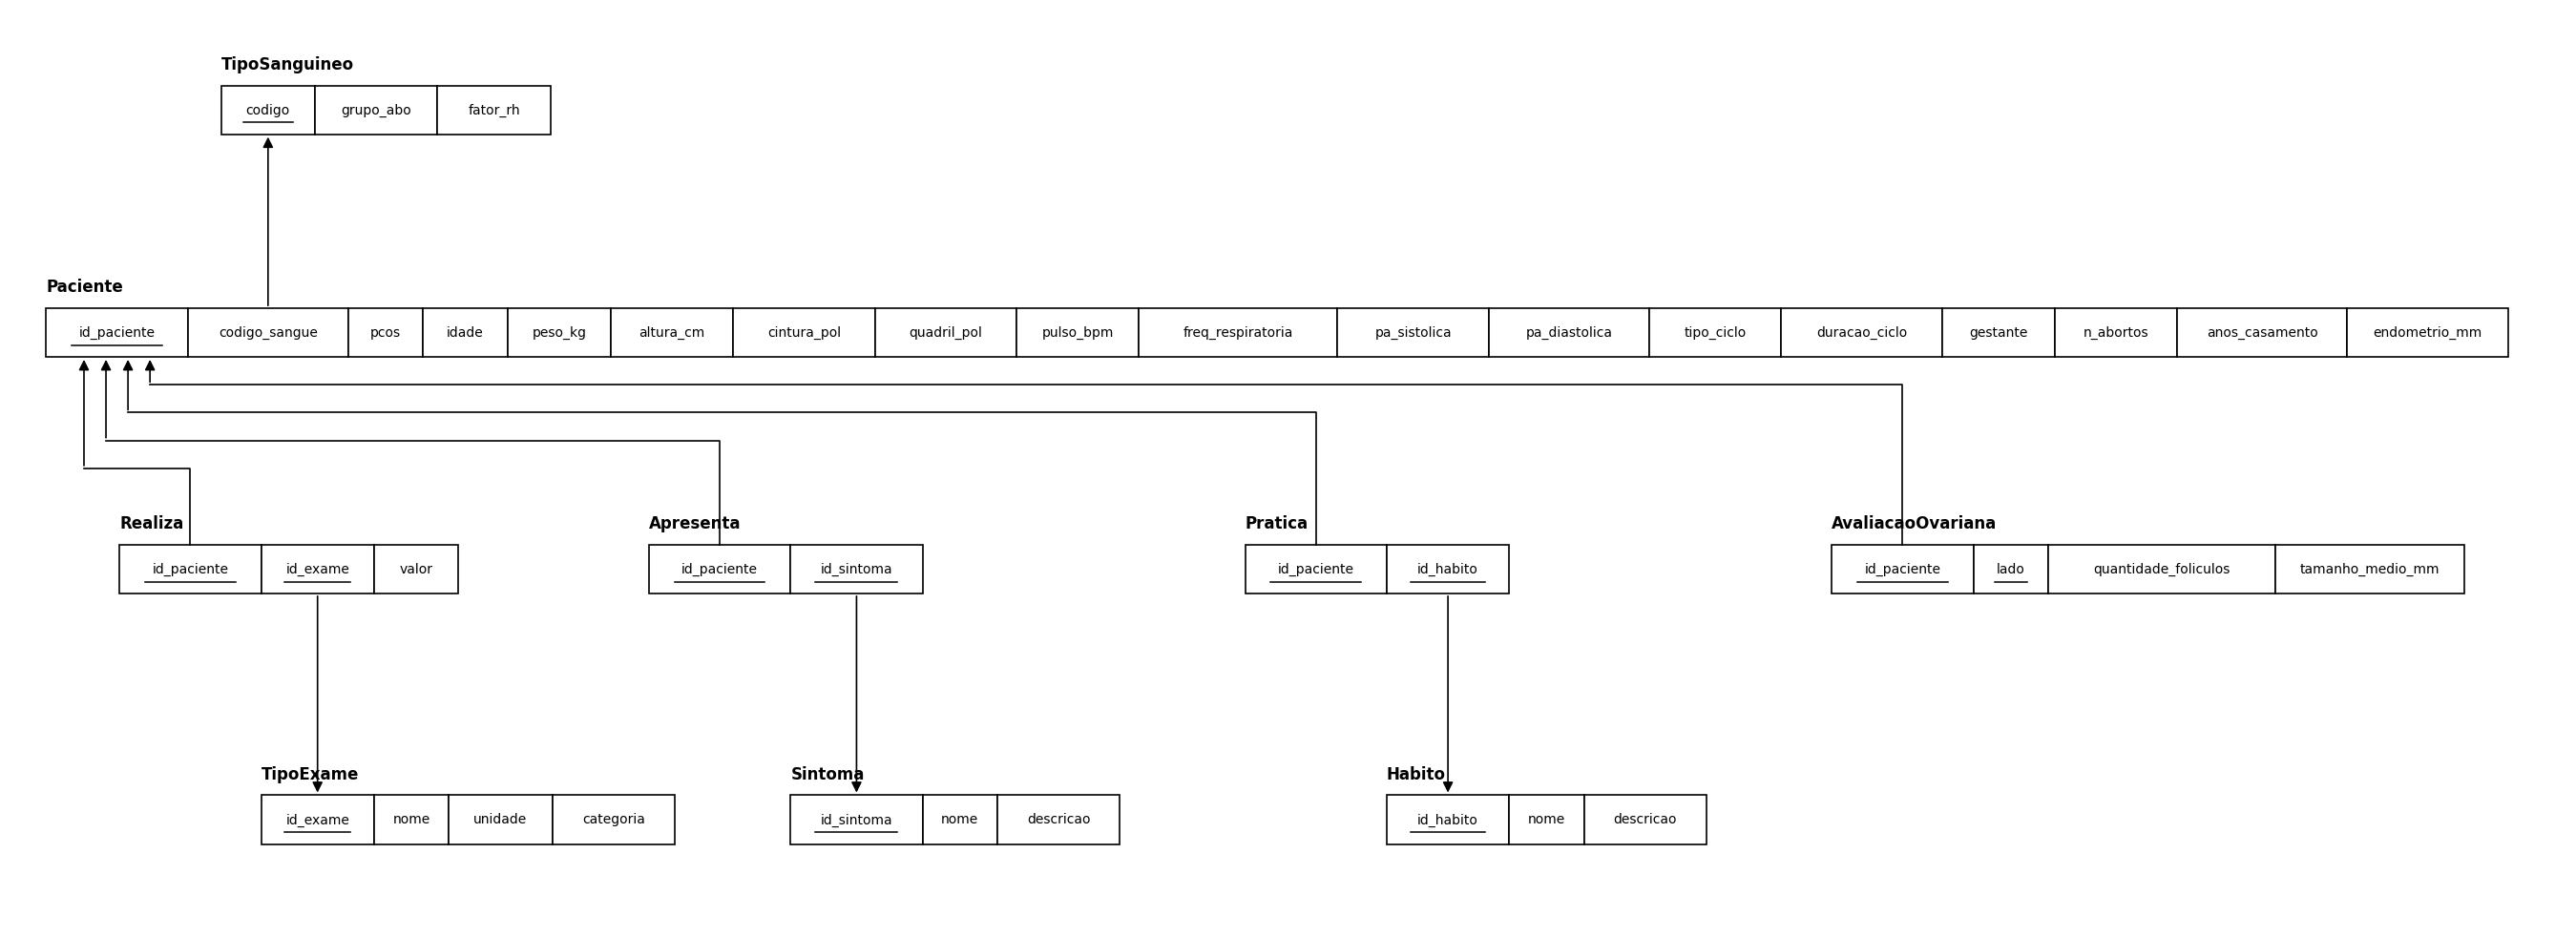

**Notação:** cada tabela é representada por suas colunas, com a chave primária sublinhada. As setas saem da chave estrangeira e apontam para a chave primária referenciada.


**Esquema relacional:**

TipoSanguineo (<u>codigo</u>, grupo_abo, fator_rh)

Paciente (<u>id_paciente</u>, codigo_sangue, pcos, idade, peso_kg, altura_cm, cintura_pol, quadril_pol, pulso_bpm, freq_respiratoria, pa_sistolica, pa_diastolica, tipo_ciclo, duracao_ciclo, gestante, n_abortos, anos_casamento, endometrio_mm)<br>
&nbsp;&nbsp;&nbsp;&nbsp;codigo_sangue REFERENCIA TipoSanguineo

TipoExame (<u>id_exame</u>, nome, unidade, categoria)

Sintoma (<u>id_sintoma</u>, nome, descricao)

Habito (<u>id_habito</u>, nome, descricao)

Realiza (<u>id_paciente, id_exame</u>, valor)<br>
&nbsp;&nbsp;&nbsp;&nbsp;id_paciente REFERENCIA Paciente<br>
&nbsp;&nbsp;&nbsp;&nbsp;id_exame REFERENCIA TipoExame

Apresenta (<u>id_paciente, id_sintoma</u>)<br>
&nbsp;&nbsp;&nbsp;&nbsp;id_paciente REFERENCIA Paciente<br>
&nbsp;&nbsp;&nbsp;&nbsp;id_sintoma REFERENCIA Sintoma

Pratica (<u>id_paciente, id_habito</u>)<br>
&nbsp;&nbsp;&nbsp;&nbsp;id_paciente REFERENCIA Paciente<br>
&nbsp;&nbsp;&nbsp;&nbsp;id_habito REFERENCIA Habito

AvaliacaoOvariana (<u>id_paciente, lado</u>, quantidade_foliculos, tamanho_medio_mm)<br>
&nbsp;&nbsp;&nbsp;&nbsp;id_paciente REFERENCIA Paciente

**Mapeamento ER → relacional:**
- Entidades fortes viram tabelas com a própria chave primária.
- **POSSUI (N:1):** chave estrangeira `codigo_sangue` no lado N (Paciente).
- **REALIZA, APRESENTA e PRATICA (M:N):** tabelas próprias, com chave primária composta pelas chaves das duas entidades; `valor`, atributo do relacionamento, fica em Realiza.
- **AvaliacaoOvariana (fraca):** chave primária = chave da dona (`id_paciente`) + chave parcial (`lado`).
- Atributos compostos são representados apenas pelos componentes simples; atributos derivados não são armazenados.

**Restrições de integridade implementadas:** chave primária e integridade de entidade (chaves não nulas); integridade referencial em todas as chaves estrangeiras, com remoção **bloqueada** (padrão) para TipoSanguineo, TipoExame, Sintoma e Habito e **propagada** (`ON DELETE CASCADE`) da paciente para Realiza, Apresenta, Pratica e AvaliacaoOvariana; restrições de domínio com `CHECK` (`pcos`, `gestante`, `tipo_ciclo`, `lado`, `grupo_abo` e `fator_rh`).

# 6. Declaração de Uso de Inteligência Artificial

*Nesta seção, declaramos como ferramentas de Inteligência Artificial (IA) foram utilizadas durante o desenvolvimento deste trabalho.*

**1\. Ferramentas utilizadas**

Anthropic Claude Code com Opus 5.5 via extensão do VSCode

**2\. Finalidades de uso**

Código: auxílio na escrita e depuração de funções e laços de tratamento de dados e sugestões de otimizações.
Texto: revisão ortográfica e gramatical e sugestões na estrutura e organização dos capítulos
Aprendizado: Contextualização sobre os dados, ajuda com definições de PostgreSQL e conceitos da disciplina.3. O que não foi feito com IA

**3\. O que não foi feito com IA**

A definição do problema, a modelagem do banco, a execução dos experimentos e os resultados foram feitos e discutidos pelos autores. 
As métricas extraídas também foram conferidas pelos autores e os diagramas foram todos gerados e desenhados sem o auxílio de ferramentas de IA. 

**4\. Verificação e responsabilidade**
Todo conteúdo gerado ou sugerido por IA foi revisado, testado e, quando necessário, modificado pelos autores. Os autores assumem total responsabilidade pelo conteúdo final do relatório, incluindo eventuais erros.